In [1]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# numpy casting helper function
def to_numpy(tensor):
    """np.gradient needs a numpy array: pass numpy straight through, otherwise
    detach the torch tensor from the graph and convert."""
    if isinstance(tensor, np.ndarray):
        return tensor
    return tensor.detach().cpu().numpy()

## Collapsed Maxwell Equations

Conductivity-weighted Poisson problem with homogeneous Neumann boundary condition (perfectly insulating boundaries):

$$
\begin{cases}
\nabla \cdot (\sigma \nabla \phi) = -I & \text{in } \Omega \\[4pt]
\sigma \dfrac{\partial \phi}{\partial \mathbf{n}} = \sigma \nabla \phi \cdot \mathbf{n} = 0 & \text{on } \partial\Omega
\end{cases}
$$

The current source density $I(x)$ is interpreted as the volume density of current entering or leaving the extracellular medium at position $x \in \Omega$. A
negative CSD corresponds to current leaving the extracellular medium
(due to the bre transmembrane currents) and is thus conventionally
called a sink. Likewise, current entering the extracellular medium is
called a source (excerpt from the paper below)

**Reference**: <br>
maksymenko2023, <br>
author  = {K. Maksymenko and A. K. Clarke and I. {Mendez Guerra} and S. Deslauriers-Gauthier and D. Farina}, <br>
title   = {A myoelectric digital twin for fast and realistic modelling in deep learning}, <br>
journal = {Nature Communications}, <br>
volume  = {14}, <br>
pages   = {1600}, <br>
year    = {2023}, <br>
doi     = {10.1038/s41467-023-37238-w}

Here $\Omega \ \subseteq \mathbb{R^2}$ because we are in 2D. <br>

In this notebook, we shall consider the tissue conductivity tensor $\sigma$ to be homogeneous and anisotropic.

The differential equation itself can never be homogeneous as we require $I \neq 0$, where $I$ is the current source density. In the inverse problem, this is the parameter we aim to retrieve given $\phi$ (our data) from the sEMG readings.

Therefore, our equation simplifies to:
$$
\sigma \nabla^2 \phi(x) = -I(x)
$$

where $I \neq 0$, $x \in \mathbb{R}^2, \sigma \in \mathbb{R}^{2 \times 2}$.

In line with the biology outlined in the *2013 Volume conductor models in surface electromyography* paper by Lucas Mesin (add reference), we take the electrical conductivity along the muscle fibre to be 5 times stronger than in the orthogonal direction. In this 2D case, we will put the fibres along the y-axis.



The off-diagonals of $\sigma$ are zero because the fibre axis is aligned with a grid axis. If the fibres run diagonal to the mesh, $\sigma$ is no longer diagonal and mixed derivatives appear - our 7-point stencil is no longer sufficient.


Therefore, we have $\sigma = \begin{pmatrix} \sigma_{T} & 0 \\ 0 & \sigma_{L} \ \end{pmatrix} = \begin{pmatrix} 1 & 0 \\ 0 & 5 \ \end{pmatrix}$.

Where $\sigma_{T}$ is the conductivity in the transverse/orthogonal direction and $\sigma_{L}$ in the longitudinal direction (along the fibre).

This time our tissue conductivity-weighted operator to the ordinary Laplacian becomes $\nabla^2 \phi = \partial_{xx}\phi + 5\partial_{yy}\phi$.

In [3]:
# 2D domain setup

# reproducibility
# inverse problem involves optimisation from an initial guess
torch.manual_seed(42)
np.random.seed(42)

# double precision needed throughout
# float32 causes round-off errors in the gradient when we differentiate for the inverse problem
torch.set_default_dtype(torch.float64)

# 2D domain - [0, L]^2
L = 1.0
N = 65  # number of grid points per axis

# vertex-centred structured grid
t = torch.linspace(0.0, L, N)
h = t[1] - t[0]  # constant grid spacing

X, Y = torch.meshgrid(t, t, indexing="ij") # we need this for finite differencing later
x = torch.stack([X, Y], axis=-1)

assert X.shape == Y.shape == (N, N)
assert x.shape == (N, N, 2)

print(f"Domain [0, {L}]^2 discretised with N = {N} points per axis ({N**2:,} total grid points)")
print(f"Grid spacing h = {h.item():.6f} = L/(N-1) = {L/(N-1):.6f}")
print(f"Coordinate grids X, Y each have shape {tuple(X.shape)}")

# quick grid spacing checks
assert torch.isclose(x[-1, -1, 1], torch.tensor(L)) # y-coordinate at corner = L
assert torch.isclose(x[-1, -1, 1] - x[-1, -2, 1], h) # spacing along y

Domain [0, 1.0]^2 discretised with N = 65 points per axis (4,225 total grid points)
Grid spacing h = 0.015625 = L/(N-1) = 0.015625
Coordinate grids X, Y each have shape (65, 65)


Point about notation, $\phi_{i,j,k}$ is shorthand for $\phi(x_{i,j,k})$, where $(i, j, k)$ are the spatial coordinates within the 3D boundary $\Omega \subseteq \mathbb{R^3}$.

We apply the same 3-point second-order central difference scheme, now in 2D and weighted by conductivity. For an interior node $(i, j)$:

$$
\nabla^2 \phi_{i,j} \approx \frac{1}{h^2}\left[ \sigma_x\left(\phi_{i+1,j}+\phi_{i-1,j}\right) + \sigma_y\left(\phi_{i,j+1}+\phi_{i,j-1}\right) - 2(\sigma_x+\sigma_y)\,\phi_{i,j} \right]\,
$$

We now substitute transverse isotropy. In 2D there is one transverse direction $x$ and one longitudinal (fibre) direction $y$, so $\sigma_x=\sigma_T$ and $\sigma_y=\sigma_L=R_a\sigma_T$, with $R_a = \sigma_L/\sigma_T$:

$$
\nabla^2 \phi_{i,j} \approx \frac{\sigma_T}{h^2}\left[ \phi_{i+1,j}+\phi_{i-1,j} + R_a\left(\phi_{i,j+1}+\phi_{i,j-1}\right) - 2(1+R_a)\,\phi_{i,j} \right].
$$

Taking $\sigma_T=1$, $R_a=5$: the $\pm x$ (transverse) faces stay at $1/h^2$, the $\pm y$ (fibre) faces become $5/h^2$, and the centre becomes $-2(1+5)/h^2 = -12/h^2$.

Now for the convolutional kernel,

In the `laplacian_kernel` layout (centre `[1,1]`, axis $0=x$, $1=y$ from `meshgrid(indexing="ij")`), the five non-zero entries are
$$
\begin{aligned}
k[1,1] &= -2(\sigma_x+\sigma_y)/h^2 = -12/h^2 && \text{(centre)} \\
k[0,1]=k[2,1] &= \sigma_x/h^2 = 1/h^2 && (\pm x,\ \perp) \\
k[1,0]=k[1,2] &= \sigma_y/h^2 = 5/h^2 && (\pm y,\ \parallel \text{ fibre})
\end{aligned}
$$
with the remaining 4 entries zero. This is a 5-point face-neighbour stencil, with only the weights changed.

In [4]:
# R_a = SIGMA_L / SIGMA_T = 5
# follows the theory outlined in Lucas Mesin 2013 paper
SIGMA_T = 1.0 # conductivity along orthogonal direction
SIGMA_L = 5.0 # conductivity along longitudinal direction

We need to use reflect padding like the above cell outlines because it obeys the physics of the homogeneous Neumann boundary condition (insulating boundary). Let's consider the low face of one axis (node index $0$ i.e. $\phi[0]$, where the outward normal points in the $-x$ direction). To approximate the normal derivative at the boundary node (index 0), we use a 2nd order central difference scheme centred at $\phi[0]$, which requires a ghost node at index $-1$ ($\phi[-1]$):

$\left.\dfrac{\partial \phi(x)}{\partial x}\right|_{i=0} \approx \dfrac{\phi(x_{1,j}) - \phi(x_{-1,j})}{2h}$

Now we impose the homogeneous Neumann boundary (zero flux) $\sigma \dfrac{\partial \phi}{\partial \mathbf{n}} \mathbf{n} = 0$, so we set the above expression to $0$:

$\dfrac{\phi(x_{1,j}) - \phi(x_{-1,j})}{2h} = 0 \implies \phi(x_{1,j}) = \phi(x_{-1,j})$.

This yields our ghost node value of $\phi(x_{-1,j}) = \phi(x_{1,j})$, which we implement above. We follow the same method on the high side $\phi(x_{N,j}) = \phi(x_{N-2,j})$

And we set up normal derivatives similarly at the remaining $2$ sides of our domain (i.e. we do it at both the boundary nodes for each spatial direction $i, j$ to give $4$ sides in total).

In [5]:
# the boundary conditions goes on the sides of the kernel
# Computers and Fluids Paper 2026
# Neural physics: Using AI libraries to develop physics-based solvers for incompressible computational fluid dynamics
# Boyang Chen a, Claire E. Heaney b, Christopher C. Pain

In [6]:
def laplacian_kernel(h):
    """
    Implement kernel for the anistropic sigma
    """
    k = torch.zeros(3, 3)
    k[1, 1] = -2.0 * (SIGMA_T + SIGMA_L)
    k[0, 1] = k[2, 1] = SIGMA_T               # ±x face-neighbours (transverse)
    k[1, 0] = k[1, 2] = SIGMA_L               # ±y face-neighbours (longitudinal, along fibre)
    k /= h ** 2
    return k.view(1, 1, 3, 3)

In [7]:
# sanity-check
# verify the operator's centre weight (diagonal of A) against the true value
k = laplacian_kernel(h)
assert k.shape == (1, 1, 3, 3)
assert np.isclose(k[0, 0, 1, 1] * (h ** 2), -2.0 * (SIGMA_T + SIGMA_L)) # -12 at the 5:1 ratio

In [8]:
def laplacian_2D(phi, h):
    """
    2D anisotropic operator div(sigma . grad phi) for a diagonal, homogeneous
    conductivity tensor (fibres along y: sigma_x = SIGMA_T, sigma_y = SIGMA_L),
    applied as a fixed-weight 5-point-stencil conv2d.

    Reflect padding sets the ghost nodes on all four faces
    (phi[-1]=phi[1], phi[N]=phi[N-2] in each axis).
    """
    n = phi.shape[0]
    assert phi.shape == (n, n)
    phi_in  = phi.view(1, 1, n, n)                          # (batch, channel, H, W)
    phi_pad = F.pad(phi_in, (1, 1, 1, 1), mode="reflect")   # pad both spatial axes - mirror about the boundary node
    return F.conv2d(phi_pad, laplacian_kernel(h)).view(n, n)



# mode="reflect" the padded values are copies of existing interior values of phi, mirrored across each face
# take a single axis with values phi[0], phi[1], phi[2],..., phi[N-2], phi[N-1]
# after reflect padding by 1 on each side, the row becomes
# phi[1], phi[0], phi[1], phi[2],..., phi[N-2], phi[N-1], phi[N-2]
# ↑ghost--------------------------------------------------↑ghost
# i.e phi[-1] = phi[1], phi[N] = phi[N-2]

Our homogeneous Neumann boundary condition yields yet another result we need to account for. Let us integrate the governing PDE over our domain $\Omega$,

$$
\begin{aligned}
\int_\Omega -I\, dV &= \int_\Omega \nabla \cdot (\sigma \nabla\phi)\, dV && \text{by our collapsed maxwell equation} \\[2mm]
&= \oint_{\partial\Omega} \mathbf{n} \cdot (\sigma \nabla\phi)\, dS && \text{by the Divergence Theorem} \\[2mm]
&= 0 && \text{by our boundary condition} \\[2mm]
\implies \int_\Omega I\, dV &= 0\,.
\end{aligned}
$$

https://en.wikipedia.org/wiki/Divergence_theorem

This means our current source distribution has zero-mean.

The skin-air interface is the insulating boundary - we ignore the connductivity of air (as per the Lucas Mesin 2013 paper referenced in the project plan literature review).

Since there is net zero flux through $\partial\Omega$ (no current density can escape through the boundary), then intuitively the total current density injected must be the same as the amount that's absorbed i.e. the sinks and sources cancel each other out. And we can also see the algebraic justification for this above.

However, the above algebra highlights the solvability condition in the continuos case, but we are working in the discrete scenario. Therefore, to motivate our implementation of this requirement, we need to introduce some background linear algebra.

The orthogonal complement of a subspace $W$ is defined as

$$
W^{\perp} = \{\, v : v \cdot w = 0 \text{ for all } w \in W \,\},
$$

i.e. the set of all vectors which are orthogonal to every vector in $W$.

A matrix $A \in \mathbb{R}^{m \times n}$ has four fundamental subspaces:

1. $\mathrm{Row}(A)$ -- Rowspace of $A$ which is the span of the row vectors of $A$ which is a subspace of $\mathbb{R}^n$.
2. $\mathrm{Col}(A)$ -- The columnspace of $A$ is the span of the column vectors of $A$ which is a subspace of $\mathbb{R}^m$. Note this also the range of $A$ denoted $\mathrm{Range}(A)$.
3. $\mathrm{Ker}(A)$ -- The (right) null space/kernel of $A$ are the vectors that satisfy the equation $Av = 0$.
4. $\mathrm{Ker}(A^{T})$ -- The left null space of $A$ are the vectors that satisfy the equation $A^{T}v = 0$, which is equivalent to $v^{T}A = 0$.

The Fundamental Theorem of Linear Algebra (FTLA) asserts that the left null space of $A$ is the orthogonal complement of the column space of $A$ i.e. $\mathrm{Col}(A) = \mathrm{Ker}(A^{T})^{\perp}$.

For our system $A\phi = b$ to have a solution, we tautologically need $b$ to fall in the span of the column vectors of $A$ because this is how matrix-vector multiplication works. Therefore,

$$
A\phi = b \text{ has a solution} \iff b \in \mathrm{Range}(A) = \mathrm{Col}(A).
$$

And since $\mathrm{Col}(A) = \mathrm{Ker}(A^{T})^{\perp}$ by the FTLA, we have that a solution exists for $A\phi = b$ if and only if $b \in \mathrm{Ker}(A^{T})^{\perp}$ i.e. $b$ lies in the orthogonal complement of the left null space of $A$.

In the discrete case the left null space $\mathrm{Ker}(A^{T})$ is one-dimensional, which is spanned by the trapezoidal weight vector $w$ .i.e. $ \ker(A^{\mathsf{T}}) = \operatorname{span}\{w\} = \{\, c\,w : c \in \mathbb{R} \,\}.$ Therefore, requiring $b$ to be orthogonal to all of $\mathrm{Ker}(A^{T})$ collapses to the single scalar condition $w^{T} b = 0$, which is the discrete solvability condition. The source $b$ must satisfy this condition for $A\phi = b$ to have a solution, which is the discrete analogue of the continuous $\int_{\Omega} I \, dV = 0$ requirement.

We implement this in the impose_net_zero_CSD function below:

In [9]:
# Claude code helped scale up the 1D version of the function to 2D

# 2D rewrite of the zero_mean_condition

def impose_net_zero_CSD(I): # current source density (CSD)
    """
    Project a 2D source field v (shape (N, N)) onto the zero-(weighted-)mean
    subspace so that the discrete system A phi = v is solvable.

    Theory (markdown cell above): integrating the PDE over Omega with the
    homogeneous Neumann BC gives the compatibility condition ∫_Ω I dA = 0.
    The discrete analogue is the solvability condition w·v = 0, where w is the
    LEFT null vector of the reflect-padded Laplacian A (i.e. A^T w = 0). On this
    vertex-centred grid that left null vector is exactly the 2D trapezoidal
    quadrature weight field, so w·v is the trapezoidal estimate of ∫_Ω I dA.
    Subtracting the trapezoidal-weighted mean makes any input field admissible.
    """
    n = I.shape[0]

    assert I.shape == (n, n) # verify I is a square

    # 1D trapezoidal weights along a single axis: every node has weight 1, except
    # the two end (boundary) nodes which get weight 1/2 (vertex-centred trap rule).
    w_axis = torch.ones(n)                 # start with weight 1 at every node
    w_axis[0] = w_axis[-1] = 0.5           # halve the two boundary nodes of [0, L]

    # 2D quadrature weight field = outer product of the 1D weights over both axes,
    # so W[i,j] = w_axis[i] * w_axis[j]. This is the discrete left
    # null vector of A; corners get 1/4, edges 1/2, interior 1.
    W = torch.einsum("i,j->ij", w_axis, w_axis)   # shape (N, N)

    # Trapezoidal-weighted mean of v: (W·v)/(W·1). The common h^2 area factor
    # cancels top and bottom, so this equals (∫v dA)/(∫1 dA) on the grid.
    weighted_mean = (W * I).sum() / W.sum()   # scalar constant to remove

    # Subtract that constant from every node.
    # Then W·(v - weighted_mean) = W·v - weighted_mean*(W·1) = 0,
    # so the projected field satisfies the
    # discrete compatibility condition exactly and A phi = v is now solvable.
    I_net_zero = I - weighted_mean

    # .item() pulls out a Python float so the check works even when I requires grad
    # (e.g. I_hat in the inverse problem); np.isclose on a grad tensor would call
    # .numpy() on it and raise a RuntimeError.
    assert np.isclose((W * I_net_zero).sum().item(), 0) # verify all the sources and sinks cancel out

    return I_net_zero


An important **design choice** we make as a result of the maths:

For any solution $\phi$, we have $\forall c \in \mathbb{R}$, we have $\nabla(\phi + c) = \nabla\phi$. <br> Therefore, the following hold:

$$\nabla \cdot \big(\sigma \nabla(\phi + c)\big) = \nabla \cdot (\sigma \nabla\phi) = -I,$$

$$\mathbf{n} \cdot \big(\sigma \nabla(\phi + c)\big) = \mathbf{n} \cdot (\sigma \nabla\phi) = 0.$$

So $\phi$ is only defined up to an additive constant, this motivates us to impose a further constraint (that we can choose) to ensure uniqueness of a solution.

Since $\phi$ is defined up to a constant, we have that our matrix $A$ (the discretisation of the continous operator $\nabla ^2 \phi$) has a (right) null space that is solved by a non-zero constant vector (i.e. a one-dimensional null space), so to obtain a unique solution, we impose a further constraint on the potential $\phi$. Which we do below:

Note - since $A$ is asymmetric, it's right and left null spaces need not coincide, which we can see in our scenario.

In [10]:
# Design choice:
# Myoelectric paper page 9 - LHS of page - use and reference their explanation
# "obtain a unique solution to the system of Eq. (2), we constrain potentials v to have a zero sum"
# This is how they ensure uniqueness
# this is what we will implement in this demo
# https://www.nature.com/articles/s41467-023-37238-w

def impose_electric_potential_uniqueness(phi):
    """
    Impose uniqueness of phi by constraining the potentials to have 0 sum, as outlined in the linked paper.
    """
    unique_phi = phi - phi.mean() # subtracting the mean yields the unique solution
    # .item() keeps this check valid when phi requires grad (inverse problem) -
    # np.isclose on a grad tensor would try to call .numpy() and raise a RuntimeError.
    assert np.isclose(unique_phi.sum().item(), 0) # verify zero sum condition we want

    return unique_phi

# phi is only defined up to an additive constant due to A·1 = 0 (see the Myoelectric digitial twin paper)
# operator is singular and the source zero-mean;
# impose_phi_uniqueness selects the additive constant in the one-parameter
# family phi + c by constraining the potentials to have zero sum

Recall in the volume-conductor model, tissue is a passive conductor. <br>
$\nabla\cdot(\sigma\nabla\phi) = -I$, where $I$ is the current source density; at each point in the cube, how much electric current is being injected into the extracellular medium (per unit area, Amperes/m^2). <br> Where $I > 0$, current is being pushed into the medium (source). Where $I < 0$, current is being drawn out (sink). <br> Recall we also derived earlier $\int_\Omega I\, dV = 0$. Which means no current escapes through the faces of the cube. Any injected current must go out of a sink somewhere inside, i.e. every source must be sunk.

The physical source is the intracellular action potential, set up by ionic currents crossing the muscle-fibre membrane. The standard representation is a current dipole: a point source $(+)$ and an equal point sink $(-)$ (Malmivuo & Plonsey, 1995, Ch. 8.2.2, https://www.bem.fi/book/). This respects current conservation by construction, which our insulated homogeneous Neumann boundary mandates. Therefore, we use a source–sink pair when creating $I_{\text{true}}$

We replace each ideal point with a Gaussian blob (see below) of finite width. A point source is a Dirac delta — singular and unresolvable on a finite grid. Whereas a Gaussian is a smooth stand-in that recovers the point in the zero-width limit. A width of several grid spacings keeps both $I$ and $\phi$ smooth and accurately solvable, while still actualising the source-minus-sink dipole.

We initialise the ground truth as the difference of two isotropic 2D Gaussian blobs — a source $(+)$ and a sink $(-)$. For a blob centred at $\mathbf{c} = (c_x, c_y)$ with width $w$,

$$
g(\mathbf{x}) = \exp\!\left(-\frac{\lVert \mathbf{x} - \mathbf{c}\rVert^2}{w^2}\right)
= \exp\!\left(-\frac{(x - c_x)^2 + (y - c_y)^2}{w^2}\right).
$$

We place the source at $\mathbf{c}_+ = (0.35,\, 0.35)$ and the sink at $\mathbf{c}_- = (0.65,\, 0.65)$, both with $w = 0.12$, and take their difference:

$$
I_{\text{true}}(\mathbf{x}) = g_+(\mathbf{x}) - g_-(\mathbf{x})
= \exp\!\left(-\frac{\lVert \mathbf{x} - \mathbf{c}_+\rVert^2}{w^2}\right)
- \exp\!\left(-\frac{\lVert \mathbf{x} - \mathbf{c}_-\rVert^2}{w^2}\right).
$$

The $+$ blob injects current and the $-$ blob withdraws it. On the discrete grid the two do not cancel exactly (sampling and boundary truncation), so we project $I_{\text{true}}$ onto the zero-(weighted-)mean subspace to enforce $\int_\Omega I\, dA = 0$ to machine precision.

In [11]:
# now we initialise I_true (our ground-truth that we manually set)

# build I_true from two isotropic 2D Gaussian blobs: a source (+) and a sink (-)
# each blob is exp(-||x - centre||^2 / width^2), centred at distinct points in the square

width = 0.12

# Gaussian itself carries no physics - it is a smooth, compact blob that is easy to write and well-resolved on the grid

# source blob centred at (0.35, 0.35)
g_source = torch.exp(-(((X - 0.35) ** 2 + (Y - 0.35) ** 2) / width ** 2))
# sink blob centred at (0.65, 0.65)
g_sink   = torch.exp(-(((X - 0.65) ** 2 + (Y - 0.65) ** 2) / width ** 2))

assert g_source.shape == g_sink.shape == (N, N)

I_true = g_source - g_sink # source minus sink

# on the discrete grid the two blobs sums are not exactly equal
# due to sampling and boundary truncation
# project onto the zero-mean subspace
# remove the small residual net current to make the balance hold to machine precision
I_true = impose_net_zero_CSD(I_true)


print(f"I_true has shape {tuple(I_true.shape)}.")
print(f"I_true range: [{I_true.min().item():.4f}, {I_true.max().item():.4f}]")

I_true has shape (65, 65).
I_true range: [-0.9946, 0.9946]


In [12]:
# Here we will add the functions needed to implement a simple 2-grid V-cycle multigrid which I had already made and played around with early in the project
# These were originally implemented for a dense linear solve for a Poission equation
# I used Claude to help implement these functions

Implement our weighted Jacobi update step:

Matrix form (solving $A\phi = I$, with $D = \operatorname{diag}(A)$):

$$
\phi^{(k+1)} = \phi^{(k)} + \omega\, D^{-1}\big(I - A\phi^{(k)}\big).
$$

Laplacian form (here $A = \texttt{laplacian\_2D}$, so $D^{-1} = -h^2/\big(2(2\sigma_T + \sigma_L)\big)$):

$$
\phi^{(k+1)} = \phi^{(k)} + \omega\,\frac{h^2}{2(2\sigma_T + \sigma_L)}\big(\texttt{laplacian\_2D}(\phi^{(k)}, h) - I\big).
$$

In [13]:
# weighted jacobi - good to ensure convergence within spectral radius - linear algebra theory here!
def jacobi(phi, I, h, omega=2.0 / 3.0, num_iters=1):
    """
    Weighted Jacobi update. d_inv is the reciprocal of the operator diagonal,
    -2(SIGMA_T + SIGMA_L)/h^2 (= -12/h^2 at the 5:1 muscle ratio)
    """
    d_inv = -h ** 2 / (2.0 * (SIGMA_T + SIGMA_L))
    for _ in range(num_iters):
        residual = I - laplacian_2D(phi, h)
        phi = phi + omega * residual * d_inv
    return phi


**Restriction (2D extension):**

In 2D the full-weighting stencil becomes the tensor (outer) product of the 1D weights $(\tfrac14, \tfrac12, \tfrac14)$ along each axis, giving a $3 \times 3$ kernel of 9 weights:

$$
r_{2h}(I,J) = \sum_{p,\,q \,\in\, \{-1,\,0,\,1\}} w_p\, w_q \; r_h\big(2I+p,\; 2J+q\big),
\qquad w_{-1}=w_{+1}=\tfrac14,\quad w_0=\tfrac12.
$$

By geometry the 9 weights group by how many of the two offsets are $\pm1$:

- centre (coincident node, no $\pm1$): weight $\tfrac14$ — 1 node,
- edge neighbours (one $\pm1$): weight $\tfrac{1}{8}$ — 4 nodes,
- corner neighbours (two $\pm1$): weight $\tfrac{1}{16}$ — 4 nodes.

These sum to $\tfrac14 + \tfrac{4}{8} + \tfrac{4}{16} = 1$, so constants are preserved (a flat field restricts to the same flat field).

Implementation note: this is a reflect-padded, stride-2 `conv2d`. With `pad=1` the output at coarse index $J$ samples fine indices $(2J-1, 2J, 2J+1)$ per axis; the reflect padding mirrors the missing neighbour at the four faces ($\phi[-1]=\phi[1]$), which is the discrete homogeneous-Neumann condition — the same boundary treatment as `laplacian_2D`. Vertex-centred coarsening requires $N = 2^k+1$ and produces a coarse grid of size $N_c = (N+1)/2$. As in 1D, $R$ is still the adjoint of the bilinear prolongation up to a constant (see the prolongation cell below).

In [14]:
# Used Claude Code to extend the restrict function to the 2d case
def restrict(r_fine):
    """
    Full-weighting restriction (fine -> coarse), 2D.

    Input  r_fine:   (N,   N  ) with N = 2^k + 1
    Output r_coarse: (N_c, N_c) with N_c = (N + 1) // 2

    The 1D full-weighting stencil (1/4, 1/2, 1/4) becomes its 3x3 tensor product
    (a 9-point weighted average summing to 1, so constants are preserved). Implemented
    as a reflect-padded, stride-2 conv2d: with pad=1 the output at coarse index J samples
    fine indices (2J-1, 2J, 2J+1), and the reflect padding mirrors the missing neighbour
    at the faces (phi[-1]=phi[1]) - the discrete homogeneous-Neumann condition, matching
    laplacian_2D.
    """
    n = r_fine.shape[0]
    assert r_fine.shape == (n, n)
    assert (n - 1) % 2 == 0, "need N = 2^k + 1 for vertex-centred coarsening"

    w = torch.tensor([0.25, 0.5, 0.25])                       # 1D full-weighting weights
    kernel = torch.einsum("i,j->ij", w, w).view(1, 1, 3, 3)

    r_in  = r_fine.view(1, 1, n, n)
    r_pad = F.pad(r_in, (1, 1, 1, 1), mode="reflect")         # Neumann mirror at the four faces
    r_coarse = F.conv2d(r_pad, kernel, stride=2)              # stride 2: keep every other node

    n_c = (n + 1) // 2
    return r_coarse.view(n_c, n_c)

**Prolongation (2D extension):**

The 2D analogue of linear interpolation is bilinear interpolation, which is the tensor product of the 1D linear interpolation along the two axes. With the fine grid sized as $N = 2N_c - 1$ and `align_corners=True`, coarse node $J$ lands exactly on fine node $2J$, and a fine node's value depends on its position relative to the surrounding coarse nodes:

- both indices even (coincides with a coarse node): exact copy, weight $1$ — 1 coarse node,
- one odd index (midpoint of a coarse edge): average of the $2$ coarse neighbours along that axis, weight $\tfrac12$ each,
- both indices odd (centre of a coarse cell): average of the $4$ corner coarse nodes, weight $\tfrac14$ each.

The boundary needs no special Dirichlet handling here: `align_corners=True` pins the coarse endpoints onto the fine endpoints, so boundary fine nodes coincide with boundary coarse nodes and are copied exactly.

Because both operators are tensor products of their 1D counterparts, the 1D variational pairing $P_{1D} = 2\,R_{1D}^\top$ becomes, in 2D,

$$
P = 2^2\, R^\top = 4\,R^\top,
$$

the standard pairing that keeps the Galerkin coarse-grid operator $R A_h P$ symmetric whenever $A_h$ is.


In [15]:
# Used Claude Code to extend the prolong function to the 2d case
def prolong(e_coarse):
    """
    Bilinear-interpolation prolongation (coarse -> fine), 2D.

    Input  e_coarse: (N_c, N_c)
    Output e_fine:   (N,   N  ) with N = 2 * N_c - 1

    align_corners=True so the coarse endpoints land exactly on the fine endpoints:
    coarse node J maps to fine node 2J (exact copy) and each odd fine node is the
    linear average of its two coarse neighbours.
    """
    n_c = e_coarse.shape[0]
    assert e_coarse.shape == (n_c, n_c)
    n = 2 * n_c - 1

    e_in   = e_coarse.view(1, 1, n_c, n_c)
    e_fine = F.interpolate(e_in, size=(n, n), mode="bilinear", align_corners=True)
    return e_fine.view(n, n)

The recursive (multilevel) V-cycle:

The two-grid idea is applied recursively: the coarse-grid correction equation $A_{2h}\,e_{2h} = r_{2h}$ is itself solved by another V-cycle, descending through successively coarser grids until the grid is small enough to solve cheaply. This generalises the two-grid scheme to any $N = 2^k + 1$.

A single V-cycle call at grid spacing $h$ (size $n$) does the following.

**Base case** ($n \le n_{\text{base}}$, the coarsest grid):

- The operator is singular (homogeneous Neumann), so first enforce the compatibility condition $w \cdot I = 0$ on the RHS (`impose_net_zero_CSD`) — this is *compulsory* for solvability.
- Run `base_iters` Jacobi sweeps; on so few unknowns this is practically an exact solve.
- Pin the free additive constant (`impose_electric_potential_uniqueness`) — a *design choice* for uniqueness — and return.

**Recursive case** ($n > n_{\text{base}}$):

1. **Pre-smoothing** ($\nu_{\text{pre}}$ Jacobi sweeps on grid $h$) — kills high-frequency error so the residual is smooth.
2. **Residual** on grid $h$: $r_h = I - A_h \phi = I - \text{laplacian}(\phi)$.
3. **Restriction**: $r_{2h} = R\, r_h$.
4. **Recursive coarse-grid correction**: enforce compatibility on $r_{2h}$, then solve $A_{2h}\,e_{2h} = r_{2h}$ by a recursive V-cycle call on grid $2h$ with a zero initial guess, and pin the constant of the returned correction $e_{2h}$.
5. **Prolongation**: $e_h = P\, e_{2h}$.
6. **Correction**: $u \leftarrow u + e_h$.
7. **Post-smoothing** ($\nu_{\text{post}}$ Jacobi sweeps on grid $h$) — cleans up high-frequency content introduced by linear interpolation.

The recursion bottoms out at the base case; on the way back up, each level adds its smoothed correction to the finer grid. Setting $\nu_{\text{pre}} = 0$ yields the sawtooth cycle.

In [16]:
# Used Claude Code to extend the 2-grid V-Cycle function to be fully recursive

# Recursive V-cycle
def v_cycle(phi, I, h, omega = (2.0/3.0), nu_pre=2, nu_post=2, base_iters=50, n_base=3):
    """
    Recursive multilevel V-cycle for solving the linear system without the dense
    linear solve (i.e. forming the dense matrix A). Generalises to any N = 2^k + 1.
    """
    n = phi.shape[0]

    # base case - coarsest grids
    # some Jacobi sweeps practically yields an exact solve
    # Singular Neumann operator, so project the RHS for compatibility and project the result to pin the free additive constant
    if n <= n_base:
        rhs = impose_net_zero_CSD(I) # have to do this
        u = jacobi(phi, rhs, h, omega=omega, num_iters=base_iters)
        return impose_electric_potential_uniqueness(u) # design choice

    # 1. pre-smoothing using Jacobi to kill initial high-frequency error
    u = jacobi(phi, I, h, omega=omega, num_iters=nu_pre)

    # 2. compute residual
    r_fine = I - laplacian_2D(u, h) # equivalent to I - A @ phi

    # 3. restrict residual to the coarse grid
    r_coarse = restrict(r_fine)

    # 4. recursive coarse-grid correction: solve A_2h @ e = r_coarse
    h_coarse = 2.0 * h
    r_coarse = impose_net_zero_CSD(r_coarse) # project the RHS to zero-mean for compatability - net current source = 0 (charge conservation)
    e_coarse = torch.zeros_like(r_coarse)
    e_coarse = v_cycle(e_coarse, r_coarse, h_coarse,
                       omega=omega, nu_pre=nu_pre, nu_post=nu_post,
                        base_iters=base_iters, n_base=n_base)
    e_coarse = impose_electric_potential_uniqueness(e_coarse) # project the correction to remove the free constant - phi only defined up to an additive constant

    # 5. prolong correction back to the fine grid
    e_fine = prolong(e_coarse)

    # 6. apply coarse_grid correction
    u = u + e_fine

    # 7. post-smoothing using Jacobi - clean up high frequency errors which appear as a result of the interpolation
    u = jacobi(u, I, h, omega=omega, num_iters=nu_post)

    return u

In [17]:
# Used Claude Code to implement these sanity and safety checks before we proceed with the forward and inverse solves

# ---------------- null-space checks on the assembled anisotropic operator ----------------
# A = laplacian_2D is the reflect-padded, diagonal-anisotropic operator div(sigma . grad).
# Two distinct null spaces (non-symmetric A):
# right null  ker(A)   = span{1}   -> gauge freedom (phi defined up to an additive constant)
# left  null  ker(A^T) = span{w}   -> solvability:  A phi = b needs w . b = 0,
# w = 2D trapezoidal quadrature weights

def assemble_A(n):
    """Dense A at grid size n, column by column: A[:, i] = laplacian_2D(e_i). Small n only."""
    h_n = L / (n - 1)
    n2 = n ** 2
    A = torch.zeros(n2, n2)
    for col in range(n2):
        e = torch.zeros(n2); e[col] = 1.0
        A[:, col] = laplacian_2D(e.view(n, n), h_n).reshape(-1)
    return A

def trapezoidal_weights(n):
    """Left-null candidate w: outer product of 1D trapezoidal weights (1/2 on the two faces)."""
    w = torch.ones(n); w[0] = w[-1] = 0.5
    return torch.einsum("i,j->ij", w, w).reshape(-1)

for n in (5, 9):
    A = assemble_A(n); n2 = n ** 2
    ones = torch.ones(n2); w = trapezoidal_weights(n)

    r_null = (A @ ones).abs().max().item()                  # ||A 1||      : right null = constants
    rank   = torch.linalg.matrix_rank(A, tol=1e-7).item()   # rank deficiency (expect exactly 1)
    asym   = (A - A.T).abs().max().item()                   # ||A - A^T||  : non-symmetry
    l_null = (A.T @ w).abs().max().item()                   # ||A^T w||    : left null = trapezoidal
    l_one  = (A.T @ ones).abs().max().item()                # ||A^T 1||    : constants NOT left-null
    _, _, Vh = torch.linalg.svd(A.T)                        # smallest left-singular direction of A
    cos = (Vh[-1] @ (w / w.norm())).abs().item()            # ...aligned with trapezoidal weights?

    print(f"N={n:2d}: ||A1||={r_null:.1e}  rank={rank}/{n2} (def {n2-rank})  "
          f"||A-A^T||={asym:.0f}  ||A^T w||={l_null:.1e}  ||A^T 1||={l_one:.1e}  "
          f"cos(w,trap)={cos:.6f}")

    assert r_null < 1e-9,        "constants must be in the right null space"
    assert n2 - rank == 1,       "rank deficiency must be exactly 1"
    assert asym > 0,             "operator must be non-symmetric"
    assert l_null < 1e-9,        "trapezoidal weights must be in the left null space"
    assert l_one  > 1e-6,        "constants must NOT be in the left null space"
    assert np.isclose(cos, 1.0), "left-null direction must align with the trapezoidal weights"

# production grid: dense A is infeasible (65^2 squared), so check constant-annihilation matrix-free
mf = laplacian_2D(torch.ones(N, N), h).abs().max().item()
print(f"N={N}: matrix-free ||A 1||_inf = {mf:.1e}")
assert mf < 1e-9, "constants must be annihilated on the production grid too"

print("\nAll null-space checks passed.")

N= 5: ||A1||=0.0e+00  rank=24/25 (def 1)  ||A-A^T||=80  ||A^T w||=0.0e+00  ||A^T 1||=9.6e+01  cos(w,trap)=1.000000
N= 9: ||A1||=0.0e+00  rank=80/81 (def 1)  ||A-A^T||=320  ||A^T w||=0.0e+00  ||A^T 1||=3.8e+02  cos(w,trap)=1.000000
N=65: matrix-free ||A 1||_inf = 0.0e+00

All null-space checks passed.


In [18]:
# our forward function
def forward(I, omega = (2.0/3.0), num_cycles=8, nu_pre=2, nu_post=2, base_iters=50):
    # resolution-agnostic: infer the grid size and spacing from the input field.
    # On the fixed vertex-centred domain [0, L]^2, h is fully determined by n,
    # so the SAME solver runs on the fine data grid (N) or the coarse inversion
    # grid (N_INV) with no other changes - this is what lets us invert on a
    # different mesh from the one that generated the data (no inverse crime).
    n = I.shape[0]
    assert I.shape == (n, n)
    h_grid = L / (n - 1)

    b = impose_net_zero_CSD(I)
    phi = torch.zeros(n, n)
    for _ in range(num_cycles):
        phi = v_cycle(phi, b, h_grid,
                        omega=omega, nu_pre=nu_pre, nu_post=nu_post,
                        base_iters=base_iters)
    return impose_electric_potential_uniqueness(phi)

In [19]:
b = impose_net_zero_CSD(I_true)
phi = forward(I_true)
res = torch.linalg.norm(impose_net_zero_CSD(b - laplacian_2D(phi, h)))
print(f"forward residual norm = {res.item():.3e}")

forward residual norm = 2.435e-01


### Synthetic measurement noise

A real sEMG acquisition never returns the clean forward field $\phi = \texttt{forward}(I_{\text{true}})$. We can have noise from power line interference, artifacts, inherent electrode noise and cross-talk to name a few. (cross-talk double check this as the paper linked above says we like to keep it as it makes our experiment more valid - check this later!)

We model this with additive, zero-mean, independent Gaussian noise on each grid node — the standard measurement-noise model:

$$
\phi_{\text{obs}}(\mathbf{x}) = \phi_{\text{clean}}(\mathbf{x}) + \eta(\mathbf{x}),
\qquad \eta(\mathbf{x}) \sim \mathcal{N}\!\left(0,\, \sigma^2\right)\ \text{i.i.d.}
$$

To make the noise level interpretable and grid/scale independent, we use the **relative noise** convention: the noise standard deviation is a chosen percentage $n$ of the clean field's root-mean-square amplitude,

$$
\sigma = \frac{n}{100}\,\operatorname{RMS}(\phi_{\text{clean}}),
\qquad
\operatorname{RMS}(\phi_{\text{clean}}) = \sqrt{\tfrac{1}{N^2}\textstyle\sum_{i,j} \phi_{\text{clean},\,ij}^2}\,.
$$

`NOISE_PERCENT` ($= n$) is the parameter: $n = 0$ recovers the noise-free case, and larger $n$ injects proportionally stronger measurement noise. We report the realised signal-to-noise ratio $\lVert\phi_{\text{clean}}\rVert / \lVert\eta\rVert$ so the chosen percentage can be sanity-checked.

Because the forward map is strongly smoothing (the ill-posedness discussed below), even a few percent of measurement noise is amplified when we invert for $I$ — this lever lets us probe exactly how the source recovery degrades with noise.

In [20]:
# we will add 5% Gaussian Measurement noise
# in line with the design choice from the following paper
# van den Doel, K., Ascher, U. M. and Pai, D. K.
# (2008) 'Computed myography: three-dimensional reconstruction of motor functions from surface EMG data',
# Inverse Problems, 24(6), 065010,
# doi:10.1088/0266-5611/24/6/065010

In [ ]:
# synthetic electrode measurements - generated from our ground truth parameter I_true

#  Gaussian measurement noise
NOISE_PERCENT = 3.0 # set the noise level
NOISE_SEED    = 0 # fixed seed - NOISE_PERCENT is reproducible

phi_clean = forward(I_true).detach() # noise-free synthetic field

# relative noise: sigma is NOISE_PERCENT of the clean field's RMS amplitude
rms   = phi_clean.pow(2).mean().sqrt()
sigma = (NOISE_PERCENT / 100.0) * rms

# reproducible Gaussian draw (own generator, so it is independent of any earlier RNG use)
noise_gen = torch.Generator().manual_seed(NOISE_SEED)
noise     = sigma * torch.randn(phi_clean.shape, generator=noise_gen)

potential_field_obs = phi_clean + noise # noisy synthetic measurements

# report the realised noise level (SNR)
snr = (phi_clean.norm() / noise.norm()).item() if NOISE_PERCENT > 0 else float("inf")
print(f"NOISE_PERCENT = {NOISE_PERCENT:.1f}%   sigma = {sigma.item():.3e}   "
      f"RMS(phi_clean) = {rms.item():.3e}")
print(f"SNR  ||phi_clean|| / ||noise|| = {snr:.2f}")

potential_field_obs = to_numpy(potential_field_obs) # cast to numpy array for matplotlib

NOISE_PERCENT = 3.0%   sigma = 1.776e-04   RMS(phi_clean) = 5.919e-03
SNR  ||phi_clean|| / ||noise|| = 33.38


Noise level: 3.0% Gaussian measurement noise


/tmp/ipykernel_11035/4173275302.py:8: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  vmax_I = np.abs(I_true).max()                           # symmetric colour scale


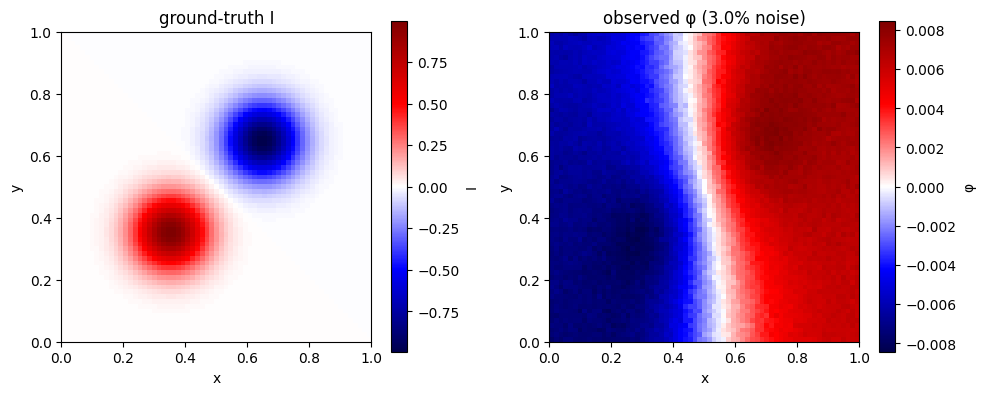

Current source density I (our ground-truth parameter)
Max value: 0.9945871416461468
Min value: -0.9945871416461468


In [22]:
# 2D fields

print(f"Noise level: {NOISE_PERCENT:.1f}% Gaussian measurement noise")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# ground-truth current source density I
vmax_I = np.abs(I_true).max()                           # symmetric colour scale
im0 = axes[0].imshow(I_true.T, origin='lower', extent=[0, L, 0, L],
                     cmap='seismic', vmin=-vmax_I, vmax=vmax_I)  # .T so x is horizontal
fig.colorbar(im0, ax=axes[0], label='I')
axes[0].set_title('ground-truth I')
axes[0].set_xlabel('x'); axes[0].set_ylabel('y')

# observed potential phi
vmax_phi = np.abs(potential_field_obs).max()            # symmetric colour scale
im1 = axes[1].imshow(potential_field_obs.T, origin='lower', extent=[0, L, 0, L],
                     cmap='seismic', vmin=-vmax_phi, vmax=vmax_phi)
fig.colorbar(im1, ax=axes[1], label='φ')
axes[1].set_title(f'observed φ ({NOISE_PERCENT:.1f}% noise)')
axes[1].set_xlabel('x'); axes[1].set_ylabel('y')

plt.tight_layout()
plt.show();

print(f"Current source density I (our ground-truth parameter)\nMax value: {I_true.max()}\nMin value: {I_true.min()}")

As we can see from sliding the gif along the z axis (to view different xy cross-sections), that in I_true we have clear distinct, sharp dipoles, however, these become completely smudged and much smaller in magnitude when we put it throught the $\texttt{forward}$ function/operator to obtain our observed $\phi$ (synthetic data).

These effects are due to the fact that the $\texttt{forward}$ map is very smoothing. The forward solve inverts the Laplacian, which divides each spatial mode of the source by its (large) eigenvalue $|\Lambda_n| = \pi^2(\sigma_x n_x^2 + \sigma_y n_y^2 )$. This  operation simultaneously erases the high-frequency content that encodes the sharp dipole edges (so the blobs blur into a diffuse field) and scales the whole field down (here $\phi_{\max}/I_{\max} \approx 1/225$).

This heavy smoothing makes our inverse problem ill-posed. The forward map damps the source's ($I$) information strongly, so recovering $I$ requires amplifying it without bound, so the recovered source $I_{\text{hat}}$ does not depend continuously on the data $\phi$. This violates the stability assumption (continuos dependence) of the Hadamaard's well-posed conditions. On our finite grid the violation appears as severe ill-conditioning, which worsens as the grid is refined.

(Note - in this experiment the ill-conditioning is the discrete manifestation of the underlying ill-posedness)

In [ ]:
# we do the inversion with a grid that has half the resolution of the forward stage
# in line with the design choice from the following paper
# van den Doel, K., Ascher, U. M. and Pai, D. K.
# (2008) 'Computed myography: three-dimensional reconstruction of motor functions from surface EMG data',
# Inverse Problems, 24(6), 065010,
# doi:10.1088/0266-5611/24/6/065010

In [24]:
# I used Claude Code to help implement the change of grid resolutions in the inversion step

### Inversion mesh resolution to avoid the "inverse crime"

We generate the synthetic measurements with the fine forward solver on the $N \times N$ grid ($N = 65$), but we invert on a coarser grid of $N_{\text{inv}} \times N_{\text{inv}}$ nodes ($N_{\text{inv}} = 33$).

Reusing the same discretisation to both simulate the data and invert is the so-called "inverse crime": the inversion becomes trivial, giving an unrealistically optimistic recovery that masks the discretisation error and ill-posedness any real experiment has.

Vertex-centred grids on $[0,L]^2$ nest exactly when $N - 1$ is an integer multiple of $N_{\text{inv}} - 1$: here $(65-1)/(33-1) = 2$, so every coarse node coincides with a fine node. We therefore read the coarse "electrode" measurements straight off the fine field at the shared nodes,

$$
\phi^{\text{inv}}_{\text{obs}}[I, J] = \phi_{\text{obs}}\big[\,s\,I,\; s\,J\,\big],
\qquad s = \frac{N - 1}{N_{\text{inv}} - 1},
$$

with no interpolation. The recovery is scored against the *same* analytic source dipole evaluated on the coarse grid, $I_{\text{true}}^{\text{inv}}$, so the error metric is consistent with the inversion resolution.

`N_INV` is the lever: `N_INV = N` deliberately commits the inverse crime (single grid); `N_INV < N` gives the crime-free coarse inversion. `N_INV` must be of the form $2^k + 1$ (the multigrid V-cycle requirement) and must divide the fine grid evenly.

In [ ]:
# inversion mesh resolution

N_INV = 33 # coarse inversion grid

# multigrid needs N_INV = 2^k + 1, and vertex-centred nesting needs the fine grid
# to be an integer refinement so every coarse node sits exactly on a fine node
assert ((N_INV - 1) & (N_INV - 2)) == 0, "N_INV must be 2^k + 1 for the V-cycle"
assert (N - 1) % (N_INV - 1) == 0,        "fine grid must be an integer refinement of the coarse grid"

stride = (N - 1) // (N_INV - 1) # fine -> coarse node stride (2 for 65 -> 33)
h_inv  = L / (N_INV - 1) # coarse grid spacing

# coarse "electrode" measurements: sample the fine field at the shared nodes
potential_field_obs_inv = to_numpy(potential_field_obs)[::stride, ::stride]
assert potential_field_obs_inv.shape == (N_INV, N_INV)

# ground truth at the inversion resolution: the same analytic dipole on the coarse grid
t_inv = torch.linspace(0.0, L, N_INV)
X_inv, Y_inv = torch.meshgrid(t_inv, t_inv, indexing="ij")
I_true_inv = impose_net_zero_CSD(
    torch.exp(-(((X_inv - 0.35) ** 2 + (Y_inv - 0.35) ** 2) / width ** 2))
  - torch.exp(-(((X_inv - 0.65) ** 2 + (Y_inv - 0.65) ** 2) / width ** 2))
)

crime = "INVERSE CRIME (single grid)" if N_INV == N else "crime-free coarse inversion"
print(f"data grid:      N     = {N:3d}  (h     = {h.item():.5f})")
print(f"inversion grid: N_INV = {N_INV:3d}  (h_inv = {h_inv:.5f})   stride = {stride}  ->  {crime}")

data grid:      N     =  65  (h     = 0.01562)
inversion grid: N_INV =  33  (h_inv = 0.03125)   stride = 2  ->  crime-free coarse inversion


In [26]:
# Inverse problem

# we recover the source on the COARSE inversion grid (N_INV) from the fine-grid
# measurements sampled at the coarse electrodes (different mesh -> no inverse crime)

I_hat = torch.zeros((N_INV, N_INV), requires_grad=True) # initial guess at 0, on the coarse grid
lr = 0.2
optimiser = torch.optim.Adam([I_hat], lr=lr)

# coarse-grid measurements (already numpy) -> tensor for the misfit
potential_field_obs_t = torch.as_tensor(potential_field_obs_inv)

I_true_norm = torch.linalg.norm(I_true_inv).item() # coarse-grid ground truth, computed once
loss_history, field_error_history = [], []

snapshot_every = 100 # store a recovered I_hat this often
I_hat_snapshots = [] # list of (iter, I_hat_np, rel_field_err)

max_iters = 2000
for i in range(max_iters):
    optimiser.zero_grad() # clear gradients for the next iteration
    potential_field_pred = forward(I_hat) # coarse forward solve (h inferred from N_INV); keep grad
    loss = 0.5 * ((potential_field_pred - potential_field_obs_t) ** 2).sum() # full field data misfit
    loss.backward() # calculate gradients by backpropagating using Jacobi
    optimiser.step() # Adam update of I_hat (update our parameter)

    loss_history.append(loss.item())

    field_error = (torch.linalg.norm(I_hat.detach() - I_true_inv)
                   / I_true_norm).item()
    field_error_history.append(field_error)

    # store a snapshot every `snapshot_every` iters (and on the final iter)
    if i % snapshot_every == 0 or i == max_iters - 1:
        I_hat_snapshots.append((i, I_hat.detach().cpu().numpy().copy(), field_error))

    if i % 100 == 0:
        print(f" step {i:3d}: data loss = {loss.item():.2e}   rel field err = {field_error_history[-1]:.3e}")


 step   0: data loss = 1.91e-02   rel field err = 1.087e+00
 step 100: data loss = 3.74e-05   rel field err = 7.112e-01
 step 200: data loss = 2.28e-05   rel field err = 5.177e-01
 step 300: data loss = 1.80e-05   rel field err = 5.079e-01
 step 400: data loss = 1.63e-05   rel field err = 5.837e-01
 step 500: data loss = 1.56e-05   rel field err = 6.697e-01
 step 600: data loss = 1.52e-05   rel field err = 7.516e-01
 step 700: data loss = 1.48e-05   rel field err = 8.297e-01
 step 800: data loss = 1.45e-05   rel field err = 9.056e-01
 step 900: data loss = 1.42e-05   rel field err = 9.805e-01
 step 1000: data loss = 1.39e-05   rel field err = 1.055e+00
 step 1100: data loss = 1.36e-05   rel field err = 1.130e+00
 step 1200: data loss = 1.34e-05   rel field err = 1.204e+00
 step 1300: data loss = 1.32e-05   rel field err = 1.279e+00
 step 1400: data loss = 1.29e-05   rel field err = 1.353e+00
 step 1500: data loss = 2.23e-05   rel field err = 1.421e+00
 step 1600: data loss = 1.26e-05  

Forward (data) resolution: 65x65   |   Inverse resolution: 33x33
Noise level: 3.0% Gaussian measurement noise


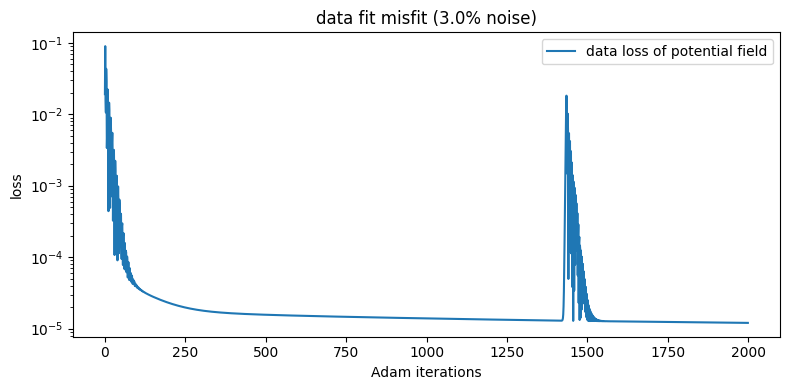

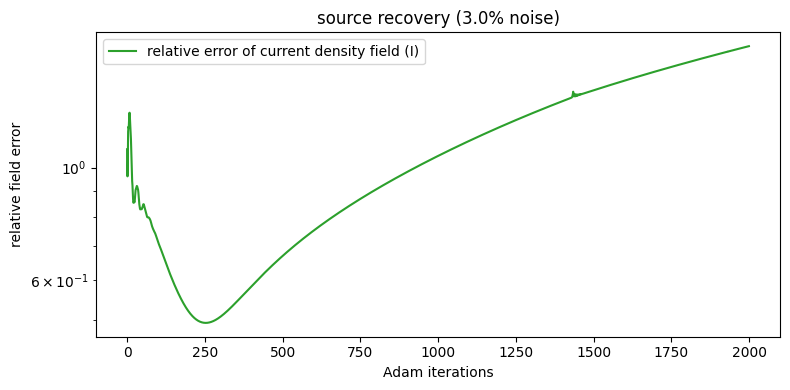

In [27]:
# convergence plots

print(f"Forward (data) resolution: {N}x{N}   |   Inverse resolution: {N_INV}x{N_INV}")
print(f"Noise level: {NOISE_PERCENT:.1f}% Gaussian measurement noise")

fig1, ax1 = plt.subplots(figsize=(8, 4))

ax1.semilogy(loss_history, label='data loss of potential field')  # phi_pred vs phi_obs mismatch
ax1.legend()
ax1.set_xlabel('Adam iterations')
ax1.set_ylabel('loss')
ax1.set_title(f'data fit misfit ({NOISE_PERCENT:.1f}% noise)')
fig1.tight_layout()

# source recovery - relative field error on its own scale
fig2, ax2 = plt.subplots(figsize=(8, 4))
ax2.semilogy(field_error_history, color='tab:green',
             label='relative error of current density field (I)') # I_hat vs I_true mismatch
ax2.legend()
ax2.set_xlabel('Adam iterations')
ax2.set_ylabel('relative field error')
ax2.set_title(f'source recovery ({NOISE_PERCENT:.1f}% noise)')
fig2.tight_layout()

plt.show();

Forward (data) resolution: 65x65   |   Inverse resolution: 33x33
Noise level: 3.0% Gaussian measurement noise


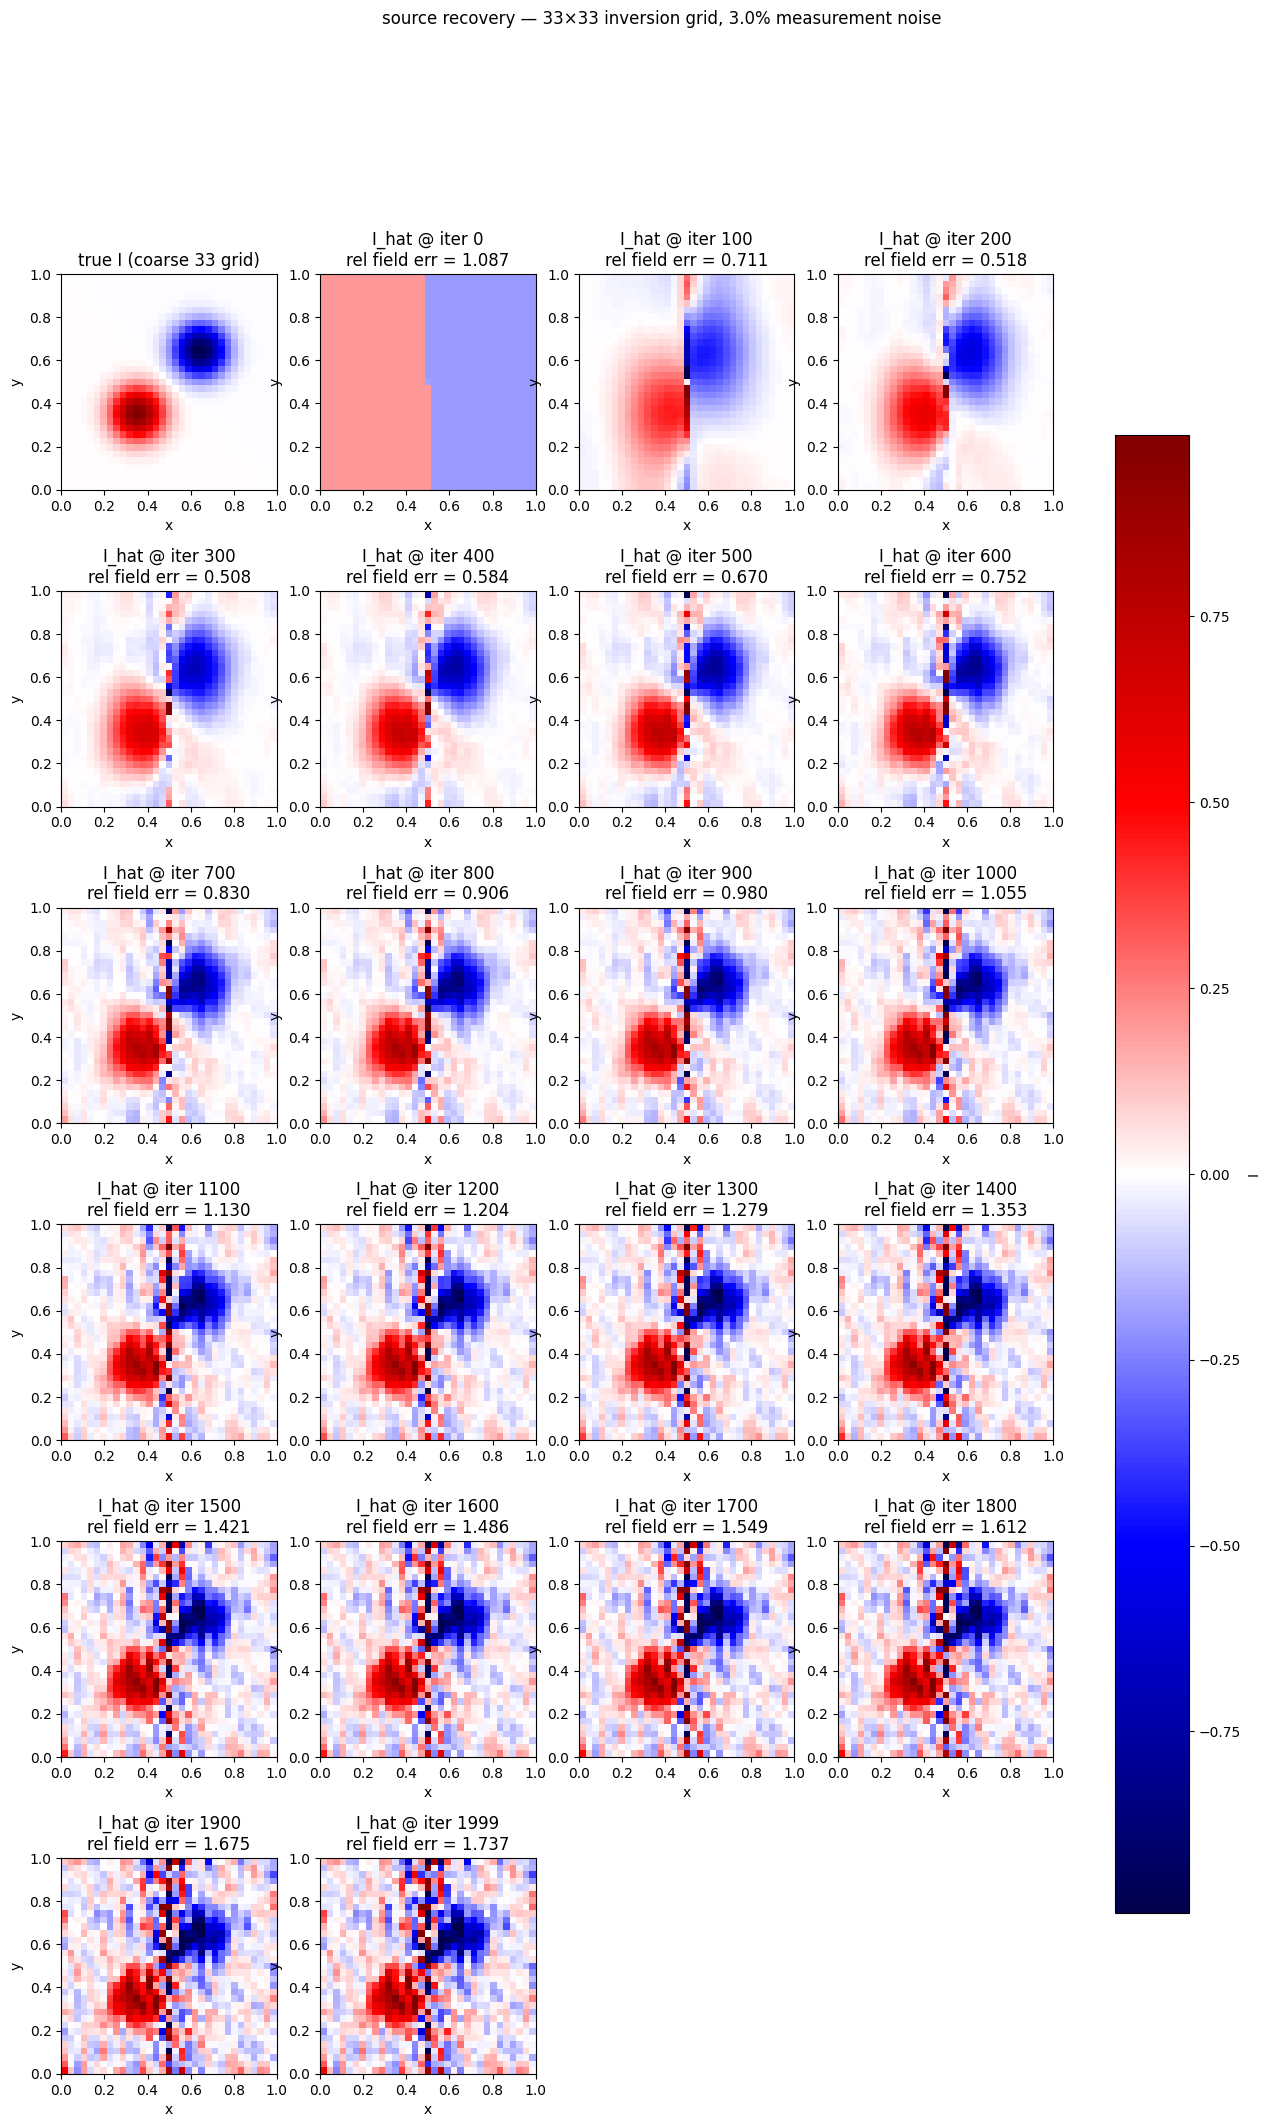

In [28]:
# ground truth vs recovered source
def _np(a):
    """torch tensor or numpy array -> numpy array."""
    return a.detach().cpu().numpy() if hasattr(a, "detach") else np.asarray(a)

print(f"Forward (data) resolution: {N}x{N}   |   Inverse resolution: {N_INV}x{N_INV}")
print(f"Noise level: {NOISE_PERCENT:.1f}% Gaussian measurement noise")

I_true_np = _np(I_true_inv)                    # coarse-grid ground truth (matches I_hat resolution)
vmax = np.abs(I_true_np).max()                 # shared symmetric colour scale

# panels: ground-truth I, then one per stored I_hat snapshot
n_panels = 1 + len(I_hat_snapshots)
ncols = min(4, n_panels)
nrows = int(np.ceil(n_panels / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows), squeeze=False)
axes_flat = axes.ravel()

# first panel: ground truth
im = axes_flat[0].imshow(I_true_np.T, origin="lower", extent=[0, 1, 0, 1],
                         cmap="seismic", vmin=-vmax, vmax=vmax)
axes_flat[0].set_title(f"true I (coarse {N_INV} grid)")
axes_flat[0].set_xlabel("x"); axes_flat[0].set_ylabel("y")

# remaining panels: recovered I_hat snapshots, each labelled with its rel field error
for ax, (it, I_hat_np, rel_err) in zip(axes_flat[1:], I_hat_snapshots):
    im = ax.imshow(I_hat_np.T, origin="lower", extent=[0, 1, 0, 1],
                   cmap="seismic", vmin=-vmax, vmax=vmax)
    ax.set_title(f"I_hat @ iter {it}\nrel field err = {rel_err:.3f}")
    ax.set_xlabel("x"); ax.set_ylabel("y")

# hide any unused axes in the grid
for ax in axes_flat[n_panels:]:
    ax.axis("off")

fig.suptitle(f"source recovery — {N_INV}×{N_INV} inversion grid, {NOISE_PERCENT:.1f}% measurement noise")
fig.colorbar(im, ax=axes, label="I", shrink=0.8)
plt.show();

## Discuss the findings

In [136]:
from IPython.display import Image, Markdown, display
import matplotlib.image as mpimg
import matplotlib.pyplot as plt

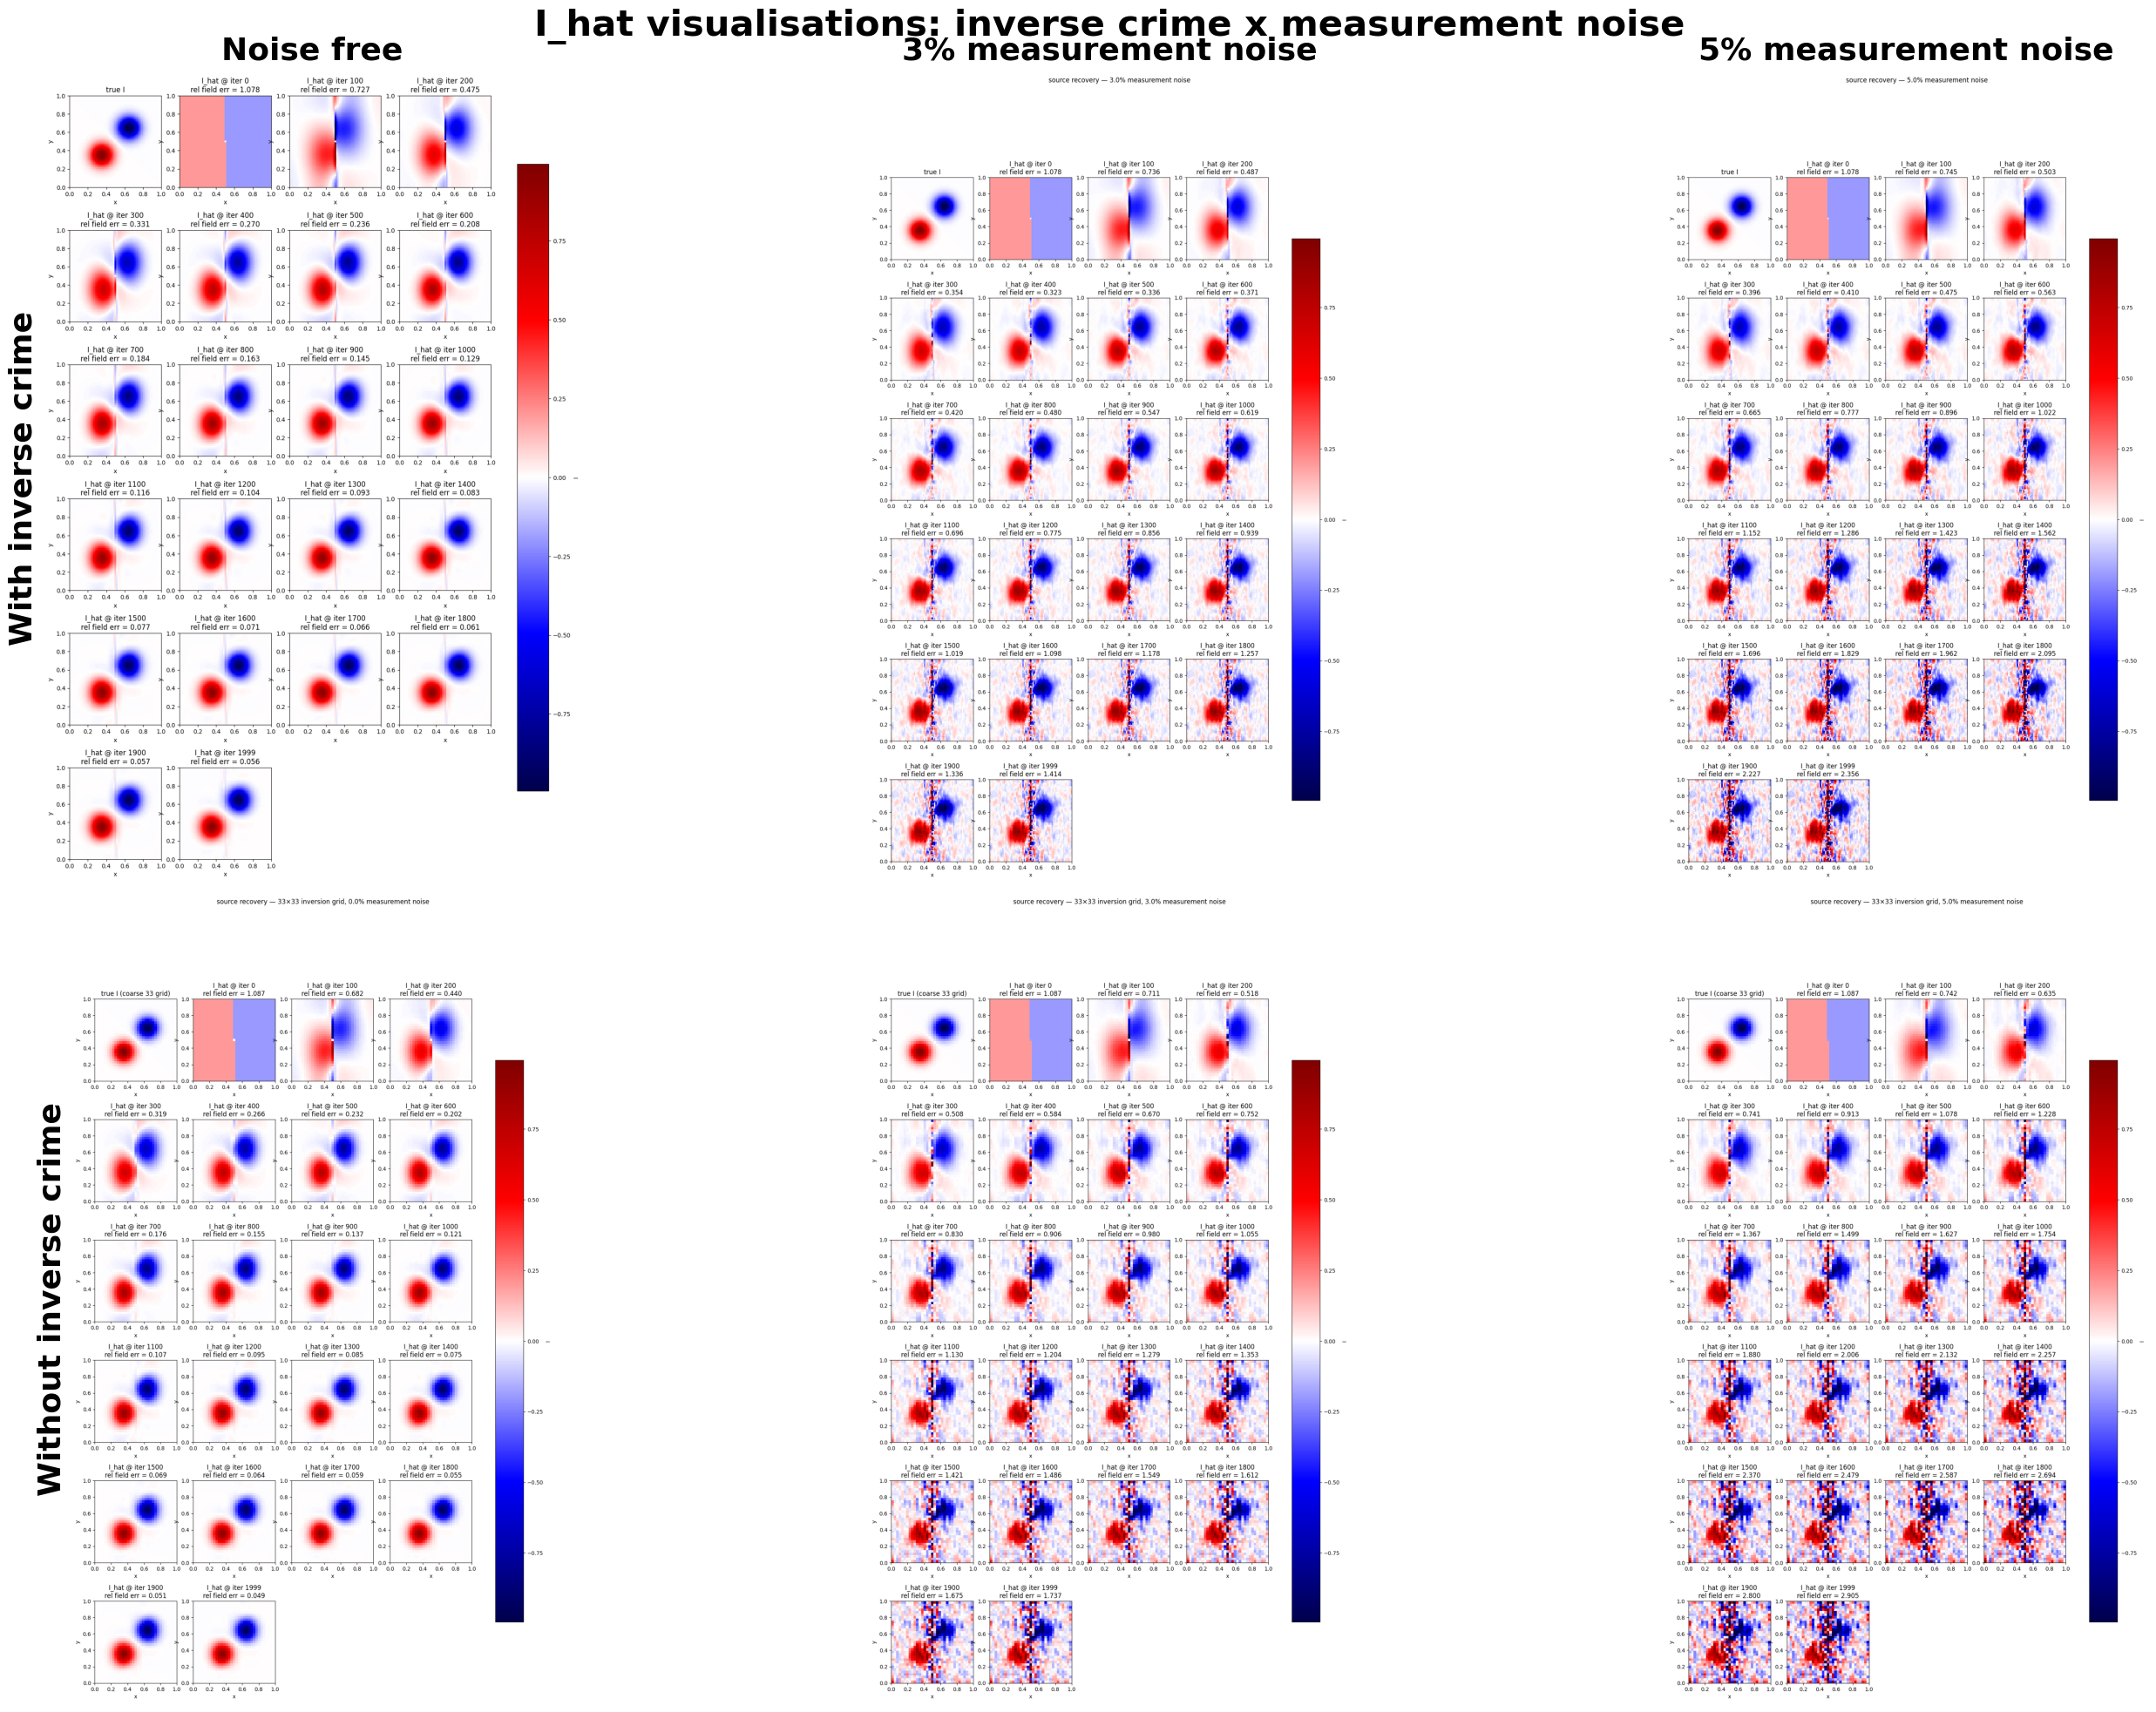

In [137]:
noise_cols = [
    ("noise-free", "Noise free"),
    ("3%-measurement-noise", "3% measurement noise"),
    ("5%-measurement-noise", "5% measurement noise"),
]

rows = [
    ("with-inverse-crime", "With inverse crime",
     ["I_hat_visualisations.png", "I_hat_visualisations_3%.png", "I_hat_visualisations_5%.png"]),
    ("without-inverse-crime", "Without inverse crime",
     ["I_hat_visualisations_no_inv_crime.png", "I_hat_visualisations_no_inv_crime_3%.png", "I_hat_visualisations_no_inv_crime_5%.png"]),
]

base = "../experiment-results/2D-experiments"

fig, axes = plt.subplots(2, 3, figsize=(30, 20))

for r, (row_dir, row_label, filenames) in enumerate(rows):
    for c, (noise_dir, noise_label) in enumerate(noise_cols):
        ax = axes[r, c]
        path = f"{base}/{row_dir}/{noise_dir}/{filenames[c]}"
        ax.imshow(mpimg.imread(path))
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)

# Column headers along the top: measurement noise level
for c, (noise_dir, noise_label) in enumerate(noise_cols):
    axes[0, c].set_title(noise_label, fontsize=26, fontweight="bold", pad=12)

# Row headers down the left: inverse crime setting
for r, (row_dir, row_label, filenames) in enumerate(rows):
    axes[r, 0].set_ylabel(row_label, fontsize=26, fontweight="bold")

fig.suptitle(
    "I_hat visualisations: inverse crime x measurement noise",
    fontsize=30, fontweight="bold",
)
fig.tight_layout()
plt.show();

As we can see too many inverse iterations hurts the reconstruction.

Under measurement noise the field error $\lVert \hat{I} - I_{\text{true}} \rVert$ does not keep improving: it falls and rises again, regardless if the data loss keeps dropping. This is *semi-convergence*, we see this behaviour of an iterative solver on an ill-posed problem, and it means the iteration count is effectively setting how strongly the problem is regularised: too many iterations causes under-regularisation.

Since the forward map is strongly smoothing, the fine-scale detail in $I$ barely registers in $\phi$. The optimiser fixes the coarse, well-observed features first (these are mostly actual signal, so the error drops initially), but once those are done the only way to keep shrinking the loss is to explain the leftover noise. Reproducing noise through a near-blind forward map demands greatly amplified fine-scale structure, which pollutes $\hat{I}$ and pushes the error back up. Hence, the data loss is a misleading guide: it falls the whole time, while the true reconstruction quality follows starts to increase again.

This happens with noise because on clean data the measurements are exactly reproducible, so fitting them fully recovers $I_{\text{true}}$ and the error never turns around. Breaking the inverse crime (coarse inversion grid) make the issue more pronounced.